In [ ]:
!pip install numpy
!pip install cupy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 54.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: Operation cancelled by user


KeyboardInterrupt: 

In [ ]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"
!pip install pycuda

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 31.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.8/101.8 kB 4.8 MB/s eta 0:00:00
  Created wheel for pycuda: filename=pycuda-2026.1-cp313-cp313-linux_x86_64.whl size=5281394 sha256=ed976983da4f9b9ab0c604539437184d03470f7f2f5bf143fe61a7c881c65d65
  Stored in directory: /root/.cache/pip/wheels/ce/26/46/c519675fcb0e5e17bab8e85b6676528c40d12d794182340e85
Successfully built pycuda


In [ ]:
kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if(row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule
kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if(row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""
mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

N = 1024
A_cpu = np.random.randn(N, N).astype(np.float32)
B_cpu = np.random.randn(N, N).astype(np.float32)

C_cpu = np.empty((N, N), np.float32)

A_gpu = cuda.mem_alloc(A_cpu.nbytes)
B_gpu = cuda.mem_alloc(B_cpu.nbytes)
C_gpu = cuda.mem_alloc(C_cpu.nbytes)

cuda.memcpy_htod(A_gpu, A_cpu)
cuda.memcpy_htod(B_gpu, B_cpu)

block_size = (32, 32, 1)

grid_size = (int(N/32), int(N/32), 1)

matrixMul(A_gpu, B_gpu, C_gpu, np.int32(N), block=block_size, grid=grid_size)

cuda.Context.synchronize()
print("wszystko git")
cuda.memcpy_dtoh(C_cpu, C_gpu)

del A_gpu
del B_gpu
del C_gpu

wszystko git


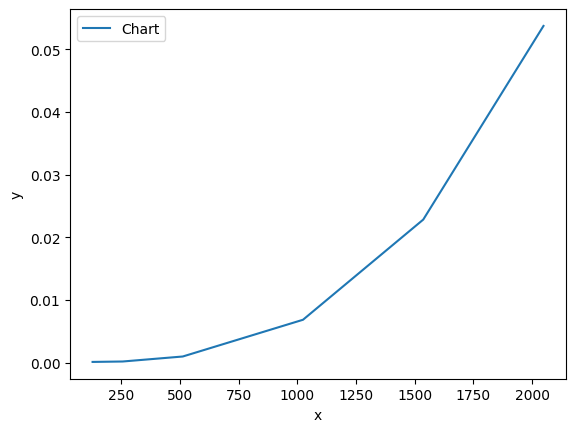

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule
import time

kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if(row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""

mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

sizes = [128, 256, 512, 1024, 1536, 2048]
times = []

for N in sizes:
    A_cpu = np.random.randn(N, N).astype(np.float32)
    B_cpu = np.random.randn(N, N).astype(np.float32)
    C_cpu = np.empty((N, N), np.float32)

    A_gpu = cuda.mem_alloc(A_cpu.nbytes)
    B_gpu = cuda.mem_alloc(B_cpu.nbytes)
    C_gpu = cuda.mem_alloc(C_cpu.nbytes)

    cuda.memcpy_htod(A_gpu, A_cpu)
    cuda.memcpy_htod(B_gpu, B_cpu)

    block_size = (32, 32, 1)
    grid_size = (int(N/32), int(N/32), 1)

    start_time = time.time()
    matrixMul(A_gpu, B_gpu, C_gpu, np.int32(N), block=block_size, grid=grid_size)
    cuda.Context.synchronize()
    end_time = time.time()

    times.append(end_time - start_time)
    cuda.memcpy_dtoh(C_cpu, C_gpu)

    del A_gpu
    del B_gpu
    del C_gpu

plt.plot(sizes, times, label="Chart")
plt.legend()
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
x = [i for i in range(1,11)]
y = [i**2 for i in range(1,11)]
plt.plot(x, y, label="Chart")
plt.legend()
plt.xlabel("x")
plt.ylabel("y")
plt.show()